['extragalactic\nlt20mag', 'extragalactic\nnew', 'sn near\ngalaxy']


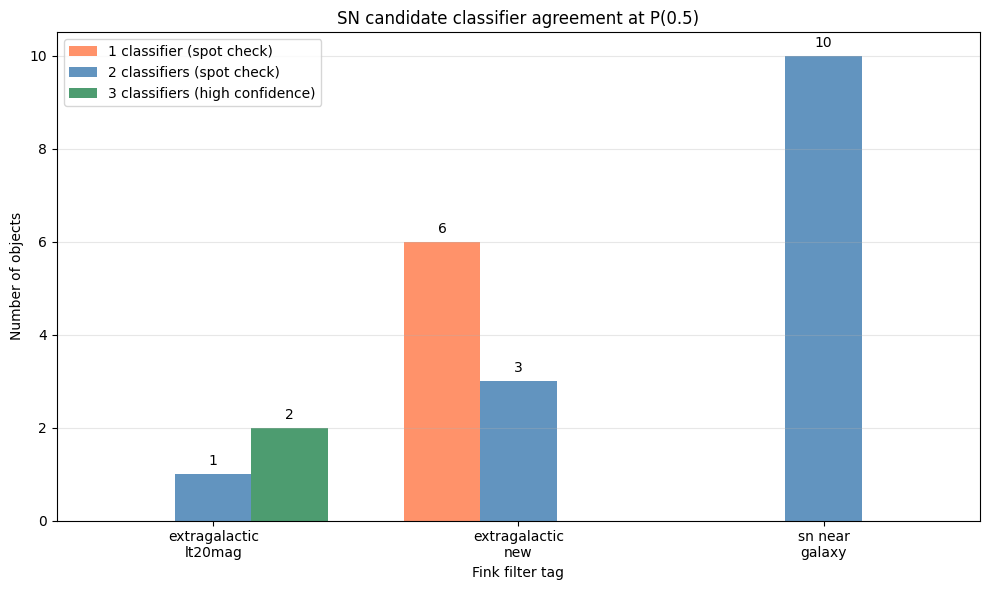

In [ ]:
# generated using Claude Sonnet 4.6 adaptive with the following prompt: "Now with the objects and their classification scores, 
# could you help me generate a plot that shows the number of objects from the acquisition pipeline that passed three, two or one classifier score cuts please?"

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base_classified_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_classified")
classified_csv_files = {
    "extragalactic\nlt20mag":    base_classified_path / "extragalactic_lt20mag_candidates_classified.csv",
    "extragalactic\nnew":        base_classified_path / "extragalactic_new_candidate_classified.csv",
    "sn near\ngalaxy":           base_classified_path / "sn_near_galaxy_candidate_classified.csv",
}

threshold = 0.5

# Count objects per tier per filter
tier_counts = {label: {1: 0, 2: 0, 3: 0} for label in classified_csv_files}

for label, path in classified_csv_files.items():
    df = pd.read_csv(path, dtype={"r:diaObjectId": str})

    mask_CATS      = (df["clf_cats_class_mode"] == 11) & (df["clf_cats_score_max"] > threshold)
    mask_EarlySNIa = df["clf_earlySNIa_max"] > threshold
    mask_snn       = df["clf_snn_max"] > threshold

    df_candidates = df[mask_CATS | mask_EarlySNIa | mask_snn].copy()
    df_candidates["n_classifiers_agree"] = (
        (df_candidates["clf_cats_score_max"] > threshold).astype(int) +
        (df_candidates["clf_earlySNIa_max"]  > threshold).astype(int) +
        (df_candidates["clf_snn_max"]        > threshold).astype(int)
    )

    for tier in [1, 2, 3]:
        tier_counts[label][tier] = len(df_candidates[df_candidates["n_classifiers_agree"] == tier])

# Plot
labels = list(tier_counts.keys())
n1 = [tier_counts[l][1] for l in labels]
n2 = [tier_counts[l][2] for l in labels]
n3 = [tier_counts[l][3] for l in labels]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width, n1, width, label="1 classifier (spot check)", color="coral",    alpha=0.85)
bars2 = ax.bar(x,          n2, width, label="2 classifiers (spot check)", color="steelblue", alpha=0.85)
bars3 = ax.bar(x + width,  n3, width, label="3 classifiers (high confidence)", color="seagreen", alpha=0.85)

# Add count labels on top of each bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f"{int(height)}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10)

ax.set_xlabel("Fink filter tag")
ax.set_ylabel("Number of objects")
ax.set_title(f"SN candidate classifier agreement at P({threshold})")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("classifier_agreement.png", dpi=150)
plt.show()

Saved to: C:\Users\riley\Documents\University\Honours\Honours_Project\images\standup_1-06-2026_alert_comparison.png


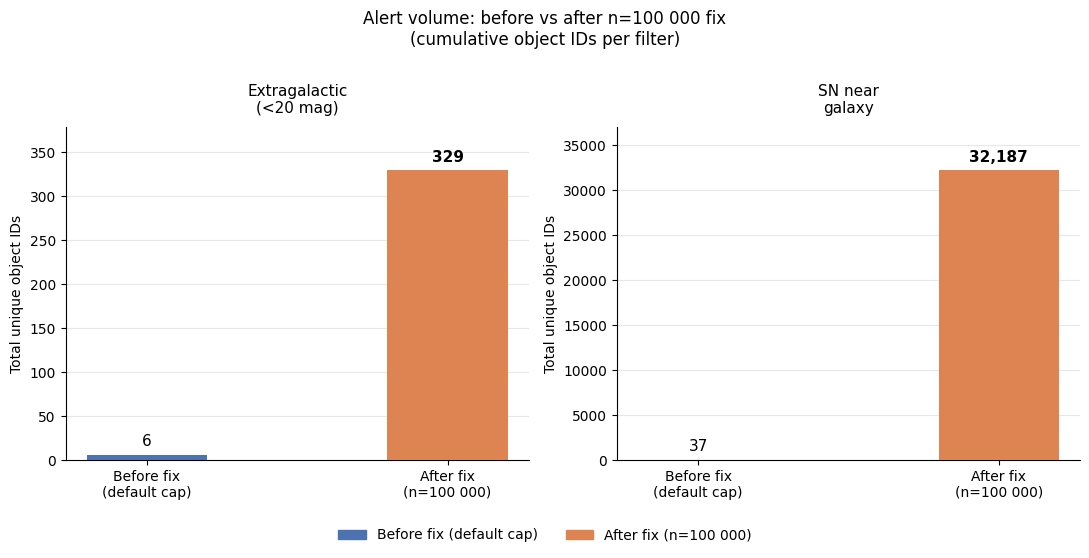

In [3]:
# Generated by: Anthropic Claude (model: claude-sonnet-4-6)
# Prompt: "Today I have a stand up meeting where I want to include the massive increase in
# alerts I now have because of the fix to the Id collection file that we made on Friday last
# week. I want to display the total number of objects I was getting with the previous filter
# before we made the changes to the n: 100000 variable in accessing the alerts. I am thinking
# bar plot with the two original filters (extragalactic with the magnitude cut and the
# SN_near galaxy_candidate) and compare them to the new variants with the number of alerts
# variable explicitly stated. Could we make those plots?"

"""
Standup bar chart: object counts before vs after the n=100000 fix.

Before fix: default API pagination cap was hit (n not explicitly set),
so counts were truncated. After fix: n=100000 explicitly passed,
pulling the full alert volume.

Reads the current CSVs for "after" counts. You supply the "before" counts
manually below (from your notes / previous run logs).
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from pathlib import Path

# ── paths ────────────────────────────────────────────────────────────────────
base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids")

csv_files = {
    "extragalactic_lt20mag": base_path / "extragalactic_lt20mag_candidate.csv",
    "sn_near_galaxy":        base_path / "sn_near_galaxy_candidate.csv",
}

# ── before counts: fill these in from your pre-fix run ───────────────────────
# (replace 0s with the actual numbers from Friday's logs)
before_counts = {
    "extragalactic_lt20mag": 6,
    "sn_near_galaxy":        37,
}

# ── read after counts from CSVs ───────────────────────────────────────────────
after_counts = {}
for tag, path in csv_files.items():
    if path.exists():
        df = pd.read_csv(path, dtype={"diaObjectId": str})
        after_counts[tag] = len(df)
    else:
        print(f"WARNING: CSV not found at {path}")
        after_counts[tag] = 0

# ── pretty labels ─────────────────────────────────────────────────────────────
label_map = {
    "extragalactic_lt20mag": "Extragalactic\n(<20 mag)",
    "sn_near_galaxy":        "SN near\ngalaxy",
}

filters = list(csv_files.keys())
x       = np.array([0, 1])   # two bars per panel: before, after
width   = 0.4
colours = ["#4C72B0", "#DD8452"]
xlabels = ["Before fix\n(default cap)", "After fix\n(n=100 000)"]

# ── two-panel figure, one subplot per filter ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("Alert volume: before vs after n=100 000 fix\n(cumulative object IDs per filter)",
            fontsize=12, y=1.01)

for ax, tag in zip(axes, filters):
    counts = [before_counts[tag], after_counts[tag]]
    bars   = ax.bar(x, counts, width, color=colours, zorder=3)

    y_max  = max(counts) if max(counts) > 0 else 1
    offset = y_max * 0.02

    for bar, val in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, val + offset,
                f"{val:,}", ha="center", va="bottom", fontsize=11,
                fontweight="bold" if val == counts[1] else "normal")

    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, fontsize=10)
    ax.set_ylabel("Total unique object IDs", fontsize=10)
    ax.set_title(label_map[tag], fontsize=11, pad=10)
    ax.set_ylim(0, y_max * 1.15)
    ax.grid(axis="y", alpha=0.3, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

# shared legend below both panels
legend_patches = [
    mpatches.Patch(color="#4C72B0", label="Before fix (default cap)"),
    mpatches.Patch(color="#DD8452", label="After fix (n=100 000)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=2,
            fontsize=10, bbox_to_anchor=(0.5, -0.08), frameon=False)

plt.tight_layout()
output = r"C:\Users\riley\Documents\University\Honours\Honours_Project\images\standup_1-06-2026_alert_comparison.png"
plt.savefig(output, dpi=150, bbox_inches="tight")
print(f"Saved to: {output}")
plt.show()

In [1]:
import pandas as pd
from pathlib import Path

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates")
rejects = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\rejection_list.csv")
SN_candidates = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN\confirmed_SN.csv")
SN_candidate_IDs = pd.read_csv(SN_candidates)["r:diaObjectId"]
reject_ids = pd.read_csv(rejects)["r:diaObjectId"]
classified_object_files = [base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_1.csv", 
                    base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_2.csv",
                    base_path / "extragalactic_lt20mag_candidates_classified_high_confidence.csv",
                    base_path / "candidates_in_TNS_classified_spot_check_required_n_1.csv",
                    base_path / "candidates_in_TNS_classified_spot_check_required_n_2.csv",
                    base_path / "candidates_in_TNS_classified_high_confidence.csv",
                    base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_1.csv",
                    base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_2.csv",
                    base_path / "sn_near_galaxy_candidate_classified_high_confidence.csv"]

for path in classified_object_files:
    df = pd.read_csv(path)
    filtered_df = df[~df["r:diaObjectId"].isin(reject_ids)]
    filtered_df = df[~df["r:diaObjectId"].isin(SN_candidate_IDs)]
    filtered_df.to_csv(path, index=False)

In [10]:
# xmatch the TNS classification in the high confidence csv file to check how well the classifiers are working. 
# starting with pulling the TNS classification from Fink
# object TNS name is under the column "f:xm_tns_fullname" and tns type is "f:xm_tns_type"
import requests as re
import pandas as pd
import io

api_url_sources = "https://api.lsst.fink-portal.org/api/v1/sources"
in_TNS_high_confidence_path = r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates\candidates_in_TNS_classified_spot_check_required_n_2.csv"
in_tns_objects_ids = pd.read_csv(in_TNS_high_confidence_path, dtype={"r:diaObjectId": str })["r:diaObjectId"]
tns_id_string = ",".join(in_tns_objects_ids.tolist())

output_path = r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN\confirmed_SN.csv"

def scrape_for_tns_name(api_url, object_ids):
    r = re.post(
        api_url,
        json={
            "diaObjectId": object_ids,
            "columns" : "r:diaObjectId, f:xm_tns_fullname, f:xm_tns_type",
            "output-format": "json"
        },
    )

    if r.status_code == 200:
        tns_names = pd.read_json(io.BytesIO(r.content))
        tns_names_filtered = tns_names[tns_names["f:xm_tns_type"].notna() & (tns_names["f:xm_tns_type"] != "nan")]
        tns_names = tns_names_filtered.drop_duplicates(subset="f:xm_tns_fullname")
        return tns_names

scrape_for_tns_name(api_url_sources, tns_id_string)

# # in_tns_object_ids is the pandas dataframe with all the data on all 51 high confidence objects, in_tns_objects_ids was defined and indexed for only the object id, in_tns_object_ids is not that.
# tns_df = pd.read_csv(in_TNS_high_confidence_path)
# tns_names_types = scrape_for_tns_name(api_url_sources, tns_id_string)
# tns_confirmed_SN_objects_full = pd.merge(tns_df, tns_names_types, on = "r:diaObjectId")
# print (tns_confirmed_SN_objects_full)
# tns_confirmed_SN_objects_full.to_csv(output_path, mode= "a", index= False, header= False)

,r:diaObjectId,f:xm_tns_fullname,f:xm_tns_type
9,170028526468595755,SN 2016cmq,SN Ia
25,314007379963805782,SN 2022and,SN II
30,170028526852374631,SN 2024adyk,SN Ia
38,170028526513684557,SN 2026asx,SN I
39,170028510831181832,TDE 2018hyz,TDE
70,170019717277810735,SN 2026ctw,SN Ia
200,170028510695916335,SN 2025mbp,SN Ia
203,170257199649521669,SN 2026kfw,SN Ia
206,170028527962292298,SN 2021ita,SN Ia
277,313998569623257167,SN 2025alrj,SN II


In [ ]:
# random sample visual inspection of in_tns active transients 
import pandas as pd
import random

tns_candidates = pd.read_csv(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates\candidates_in_TNS_classified_high_confidence.csv", dtype = {"r:diaObjectId" : str})["r:diaObjectId"]


0     170032900274651160
1     170094456400773135
2     313998569354821715
3     170019716302635146
4     170046086089015366
5     170094456334188639
6     170028486051233796
7     170050498847047681
8     170019716323082348
9     313967752817672227
10    313985346353234012
11    170094456357257301
12    313994140702998529
13    170094456365121569
14    313980947917701210
15    170028488668479507
16    170019716254926219
17    313967766285058088
18    170230797176406143
19    170235219334922248
20    170261592629837872
21    170270398108139547
22    170270398384963595
23    170270399191318556
24    170274770629689377
25    170274770671632438
26    170296772058939493
27    170226393328648251
28    170389126934167587
29    170389126953566274
30    170389126977683571
31    170389126983975053
32    170239611403501631
33    170252804532207837
34    170411112000913487
35    313963359491850270
36    313963405222871043
37    313963405286309936
38    313963406024507488
39    313963406094237721
